Execution sur runtime python 2025.07, python 3.11

In [ ]:
!pip install cython
!pip install git+https://github.com/lucasb-eyer/pydensecrf.git

  Cloning https://github.com/lucasb-eyer/pydensecrf.git to /tmp/pip-req-build-nmfocw5y
  Running command git clone --filter=blob:none --quiet https://github.com/lucasb-eyer/pydensecrf.git /tmp/pip-req-build-nmfocw5y
  Resolved https://github.com/lucasb-eyer/pydensecrf.git to commit 2723c7fa4f2ead16ae1ce3d8afe977724bb8f87f
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pydensecrf: filename=pydensecrf-1.0-cp311-cp311-linux_x86_64.whl size=3440290 sha256=acedd9a31fbff2f222e73895ee962db70e46087d1c538e7eeb4214b3f75bcfa1
  Stored in directory: /tmp/pip-ephem-wheel-cache-9tbp12ac/wheels/ce/8e/34/6dcfa200a9e2ae3627d8009b8bd1ca9b24512bec50a93304de
Successfully built pydensecrf


In [ ]:

import os
import numpy as np
import matplotlib as plt
from PIL import Image

import pydensecrf.densecrf as dcrf
from pydensecrf.utils import unary_from_softmax

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import inspect
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import preprocess_input

import zipfile, json, shutil, os

In [ ]:
IMAGE_SIZE = 321
NUM_CLASSES = 21

In [ ]:
#Dossier du dataset
DATA_DIR="/content/drive/MyDrive/Deeplab-RCP209/Dataset/segmentation-pascal-voc-2012/VOC2012_train_val/VOC2012_train_val"

In [ ]:
from google.colab import drive
drive.mount( '/content/drive',force_remount=True )

Mounted at /content/drive


Patch du modèle version python et keras antérieur

**Chargement du modèle**

In [ ]:
#on réutilise le modèle entraîné sur 100 époques
PATH_MODEL_SAVED = "/content/drive/MyDrive/Deeplab-RCP209/Models/deeplab_voc2012_best-EPO100.keras"

In [ ]:
SRC = PATH_MODEL_SAVED
FIXED = "/content/deeplab_voc2012_best-EPO100_fixed.keras"
shutil.copy(SRC, FIXED)

def strip_antialias(obj):
    if isinstance(obj, dict):
        if obj.get("class_name") == "Resizing":
            obj.get("config", {}).pop("antialias", None)
        for v in obj.values():
            strip_antialias(v)
    elif isinstance(obj, list):
        for v in obj:
            strip_antialias(v)

with zipfile.ZipFile(FIXED, "r") as zin:
    config = json.loads(zin.read("config.json"))

strip_antialias(config)

tmp = FIXED + ".tmp"
with zipfile.ZipFile(FIXED, "r") as zin, zipfile.ZipFile(tmp, "w", zipfile.ZIP_DEFLATED) as zout:
    for item in zin.infolist():
        data = zin.read(item.filename)
        if item.filename == "config.json":
            data = json.dumps(config).encode("utf-8")
        zout.writestr(item, data)
os.replace(tmp, FIXED)

In [ ]:
print(f"Chargement du modèle : {FIXED}")
model = tf.keras.models.load_model(FIXED, compile=False)
model.summary()

Chargement du modèle : /content/deeplab_voc2012_best-EPO100_fixed.keras


Model: "Deeplab"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 321, 321, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 321, 321, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 161, 161, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 161, 161, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 161, 161, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 81, 81, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 81, 81, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 81, 81, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 81, 81, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 41, 41, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 41, 41, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 41, 41, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 41, 41, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 41, 41, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 41, 41, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 41, 41, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 41, 41, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 41, 41, 1024)   │     4,719,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 41, 41, 1024)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 41, 41, 1024)   │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 41, 41, 1024)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 41, 41, 21)     │        21,525 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ upsample (Resizing)             │ (None, 321, 321, 21)   │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,505,429 (78.22 MB)

 Trainable params: 20,505,429 (78.22 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def voc_colormap():
  # palette VOC 21 classes en valeur [0,1] pour matplotlib
  def bitget(val, idx):
    return (val >> idx) & 1

  colors = []
  for i in range(21):
    r = g = b = 0
    c = i
    for j in range(8):
      r = r | (bitget(c, 0) << 7 - j)
      g = g | (bitget(c, 1) << 7 - j)
      b = b | (bitget(c, 2) << 7 - j)
      c = c >> 3
    colors.append((r / 255, g / 255, b / 255))
  return ListedColormap(colors)

VOC_CMAP = voc_colormap()

In [ ]:
#fonction d'application d'un CRF dense entièrement connecté sur les proba du réseau
#param :
# image_rgb : np.ndarray(H, W, 3) uint8 image originale non traitée, RGB [0,255] , le CRF utilise les vrais couleurs
# pour reconstituer les contours
#probs : np.ndarray (num_classes, H, W) float32   proba softmax  du réseau
# sxy_gaussian, compat_gaussian Noyau spatial (lisse localement, indépendant de la couleur)
# sxy_bilateral, srgb_bilateral : Noyau bilatéral : position + couleur -> le noyau qui "recolle" aux contours
# sxy = portee spatiale, srgb = sensibilité a la couleur
# n_iteration : nomnre d'iteration du champ moyen , paper = 10
# return labels : np.darray (H, W) int 32 - carte de classe affinée
def apply_crf(image_rgb, probs, sxy_gaussian=3, compat_gaussian=3,
              sxy_bilateral=80, srgb_bilateral=13, compat_bilateral=10, n_iterations=5):
  H, W = image_rgb.shape[:2]
  num_classes = probs.shape[0]
  d = dcrf.DenseCRF2D(W, H, num_classes)

  #Terme unaire : -log des proba du réseau
  unary = unary_from_softmax(probs)
  unary = np.ascontiguousarray(unary)
  d.setUnaryEnergy(unary)

  # Noyau gaussien (spatial seul) : lisse le bruit local
  d.addPairwiseGaussian(sxy=sxy_gaussian, compat=compat_gaussian)

  # Noyau bilatéral : position + couleur -> le noyau qui "recolle" aux contours
  d.addPairwiseBilateral(sxy=sxy_bilateral, srgb=srgb_bilateral,
                        rgbim= np.ascontiguousarray(image_rgb),
                        compat=compat_bilateral)

  # inference mean field
  Q = d.inference(n_iterations)
  labels = np.argmax(Q, axis=0).reshape((H, W)).astype(np.int32)
  return labels

In [ ]:

#prédit les proba softmax , ramenés à la taille de l'image originale
#retourne (num_classes, H, W) pour le CRF, et la carte argmax (H, W)
def predict_probs(model, image_rgb, image_size):
  H, W = image_rgb.shape[:2]
  #prétraitement identique à l'entraînement
  x = tf.image.resize(tf.cast(image_rgb, tf.float32), image_size)
  x = preprocess_input(x)
  x = tf.expand_dims(x, 0)

  #appel du modèle précédemme,nt entraîné en inférence
  logits = model.predict(x, verbose=0)[0]     #(h, W, C)
  probs = tf.nn.softmax(logits, axis=-1).numpy() #(h, W, C)

  #remise à la taille initiale (pour alignement image et masque)
  probs = tf.image.resize(probs, (H, W)).numpy()    #(H, W, C)
  pred = np.argmax(probs, axis=-1)                  #(H, W)

  probs_crf = np.transpose(probs, (2, 0, 1))        #(C, H, W) pour le CRF
  probs_crf = np.ascontiguousarray(probs_crf)
  return probs_crf, pred

#afichage sur 4  colonnes : Image dataset - Masque - Prédiction - Prédiction avec CRF
#crf_params : dictionnaire de paramètres passés à apply_crf
def show_crf_comparison(model, data_dir, split='val', num_images=4,
                        image_size=(IMAGE_SIZE, IMAGE_SIZE), voc_cmap=VOC_CMAP,
                        crf_params=None, ignore_label=255):
  if (crf_params is None):
    crf_params = {}

  images_dir = os.path.join(data_dir, "JPEGImages")
  #segmentation : masques png + splits du dataset dans /Segmentation/
  masks_dir = os.path.join(data_dir, "SegmentationClass")

  split_file = os.path.join(data_dir, "ImageSets", "Segmentation", f"{split}.txt")

  # Identifiants des images à afficher
  with open(split_file, "r") as f:
      ids = [line.strip() for line in f if line.strip()][:num_images]


  fig, axes = plt.subplots(len(ids), 4 , figsize=(15, 4 * len(ids)))
  if (len(ids)) == 1:
    axes = axes[np.newaxis, :]

  for i, images_id in enumerate(ids):
    # Colonne 1 : image du dataset

    pil_img = Image.open(os.path.join(images_dir, f"{images_id}.jpg")).convert("RGB")
    image_rgb = np.array(pil_img)
    axes[i, 0].imshow(pil_img)
    axes[i, 0].set_title(f"Image\n{images_id}") # Corrected f-string for title
    axes[i, 0]. axis("off")

    # Colonne 2 : Masques
    mask = np.array(Image.open(os.path.join(masks_dir, f"{images_id}.png")))
    mask_disp = mask.copy()
    mask_disp[mask_disp == ignore_label] = 0
    #redimensionne le masque à la taille d'affichage (nearest) pour comparer
    axes[i, 1].imshow(mask_disp, cmap=voc_cmap, vmin=0, vmax=20)
    axes[i, 1].set_title("Masque réel")
    axes[i, 1]. axis("off")

    # Prédictions du modèle
    probs_crf, pred = predict_probs(model, image_rgb, image_size)

    #application du post traitement CRF
    pred_crf = apply_crf(image_rgb, probs_crf, **crf_params)

    # Colonne 3 : prédiction
    axes[i, 2].imshow(pred, cmap=VOC_CMAP, vmin=0, vmax=20)
    # Diagnostic "fond" : proportion de pixels prédit classe 0
    axes[i, 2].set_title(f"Prédiction")
    axes[i, 2]. axis("off")

    # Colonne 4 : prédiction + CRF appliqué à la prédiction
    axes[i, 3].imshow(pred_crf, cmap=VOC_CMAP, vmin=0, vmax=20)
    axes[i, 3].set_title(f"Prédiction + CRF")
    axes[i, 3]. axis("off")
  fig.tight_layout()
  plt.show()

  return fig



In [ ]:
#calcule le MIoU sur tout le set de validation après application du traitement CRF,
#en le comparant au mIoU avant CRF
#max_images : permet de limiter le nombre d'images à traiter, le traitement CRF est lent

def eval_MIoU_avec_CRF(model, data_dir, split="val", image_size=(IMAGE_SIZE,IMAGE_SIZE),
                       num_classes=NUM_CLASSES, ignore_label=255, crf_params=None,
                       max_images=None, verbose=True):
  if (crf_params is None):
    crf_params = {}

  images_dir = os.path.join(data_dir, "JPEGImages")
  #segmentation : masques png + splits du dataset dans /Segmentation/
  masks_dir = os.path.join(data_dir, "SegmentationClass")

  split_file = os.path.join(data_dir, "ImageSets", "Segmentation", f"{split}.txt")

  # Identifiants des images à afficher
  with open(split_file, "r") as f:
      ids = [line.strip() for line in f if line.strip()]
  if max_images:
    ids = ids[:max_images]

  miou_sans_crf = tf.keras.metrics.MeanIoU(num_classes=num_classes, ignore_class=ignore_label)
  miou_avec_crf = tf.keras.metrics.MeanIoU(num_classes=num_classes, ignore_class=ignore_label)

  for k, images_id in enumerate(ids):
    # Chargement de l'image et du masque
    pil_img = Image.open(os.path.join(images_dir, f"{images_id}.jpg")).convert("RGB")
    image_rgb = np.array(pil_img)
    mask = np.array(Image.open(os.path.join(masks_dir, f"{images_id}.png")))

    # Prédictions du modèle
    probs_crf, pred = predict_probs(model, np.array(pil_img), image_size)

    #application du post traitement CRF
    pred_crf = apply_crf(image_rgb, probs_crf, **crf_params)

    #mise à jour des 2 métriques avec le masque, la classe "non annotée" de valeur 255 est ignorée
    miou_sans_crf.update_state(mask, pred)
    miou_avec_crf.update_state(mask, pred_crf)

    if verbose and (k+1) % 50 == 0:
      print(f"Images traitées : {k+1}/{len(ids)}")

  r_sans = float(miou_sans_crf.result())
  r_avec = float(miou_avec_crf.result())

  print(f"\nval_miou SANS CRF : {r_sans:.4f}")
  print(f"\nval_miou AVEC CRF : {r_avec:.4f}")
  print(f"Gain du CRF : {(r_avec - r_sans )*100:.2f} points")
  return r_sans, r_avec

**Tuning parametres CRF**

1er appel sur 100 images

In [ ]:
#valeurs du papier

crf_params = {
    "sxy_gaussian": 3,
    "compat_gaussian": 3,
    "sxy_bilateral": 80,    # portee spatiale
    "srgb_bilateral": 13,   # sensibilite couleur
    "compat_bilateral": 10, #poids du terme bilateral
    "n_iterations": 10      #valeur du papier
}



In [ ]:
miou_sans_crf, miou_avec_crf = eval_MIoU_avec_CRF(model, DATA_DIR,
                                                  split="val",
                                                  image_size=(IMAGE_SIZE,IMAGE_SIZE),
                                                  crf_params = crf_params,
                                                  num_classes=NUM_CLASSES,
                                                  max_images=100)

Images traitées : 50/100
Images traitées : 100/100

val_miou SANS CRF : 0.2732

val_miou AVEC CRF : 0.3018
Gain du CRF : 2.85 points


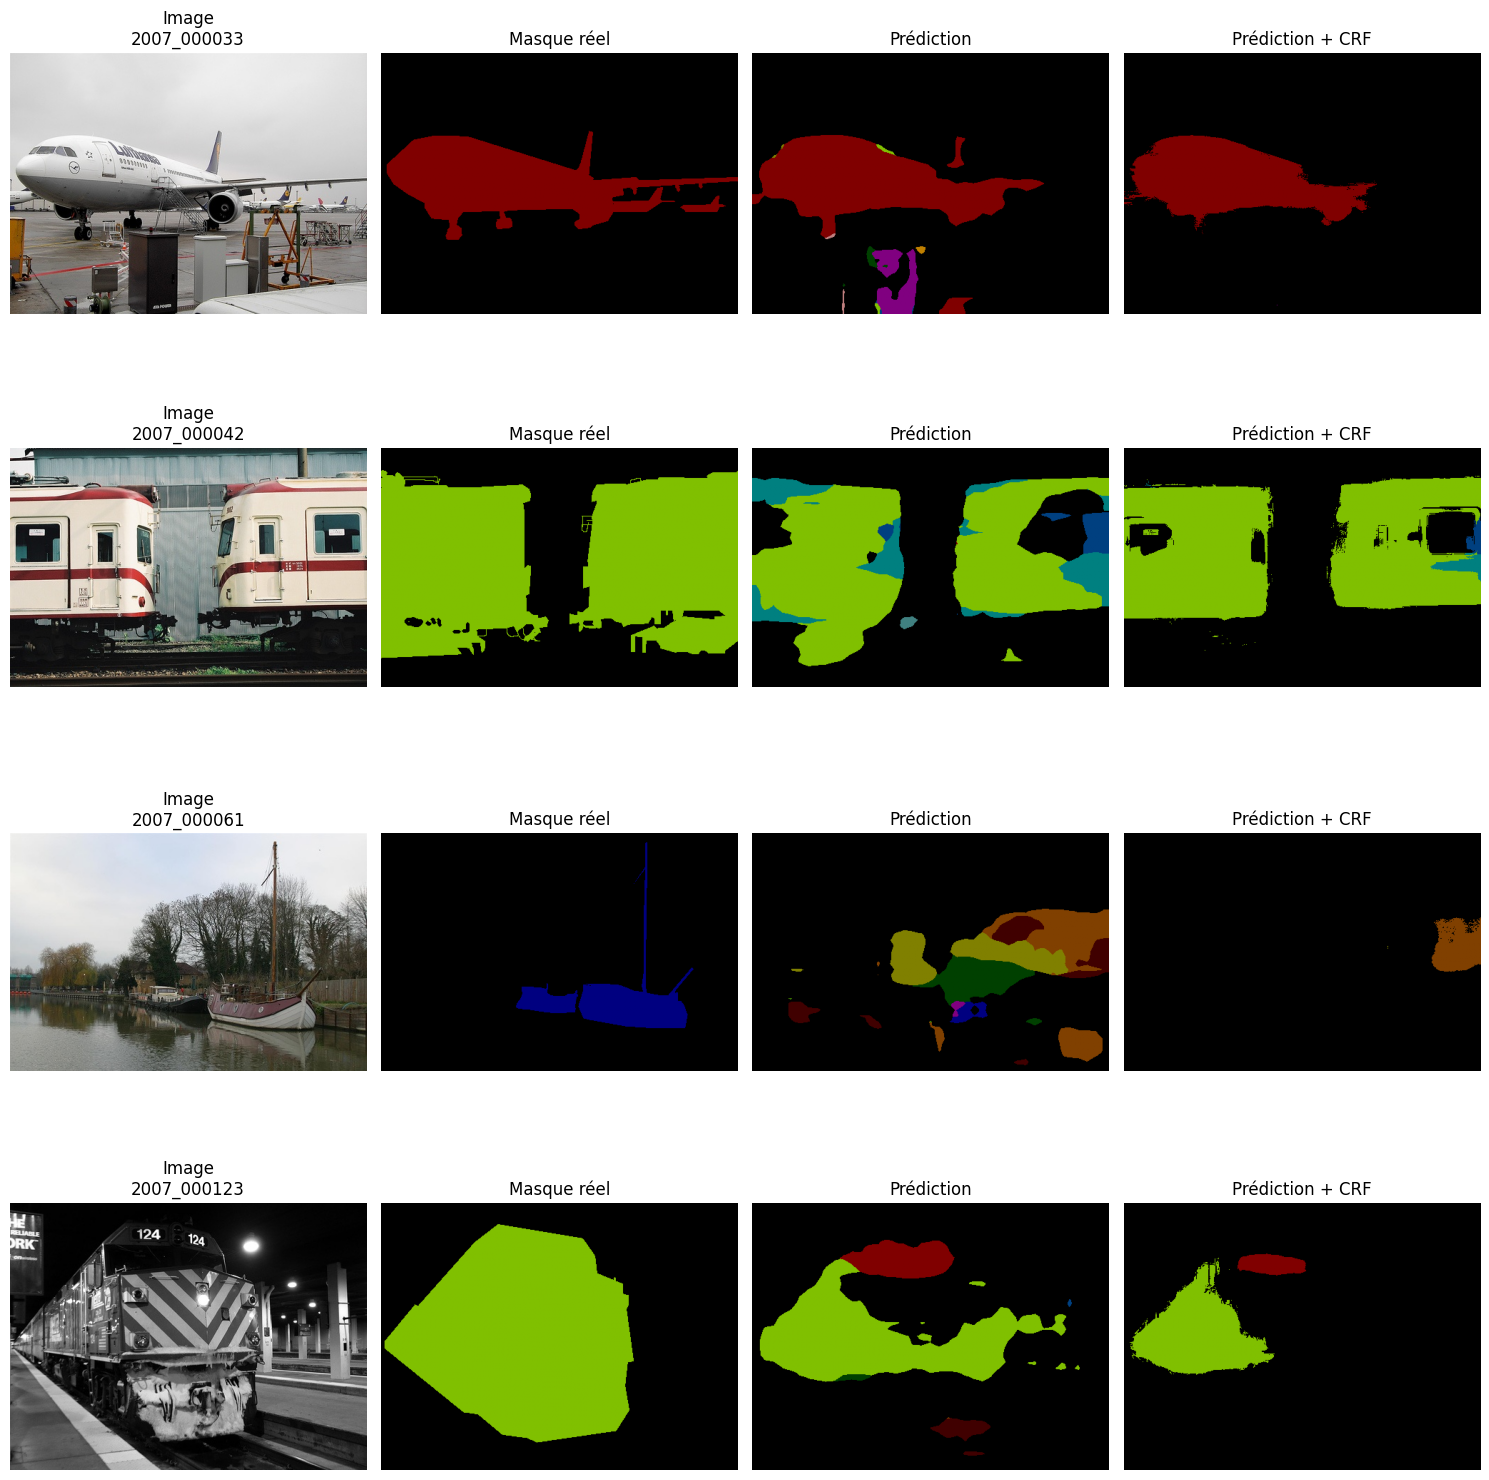

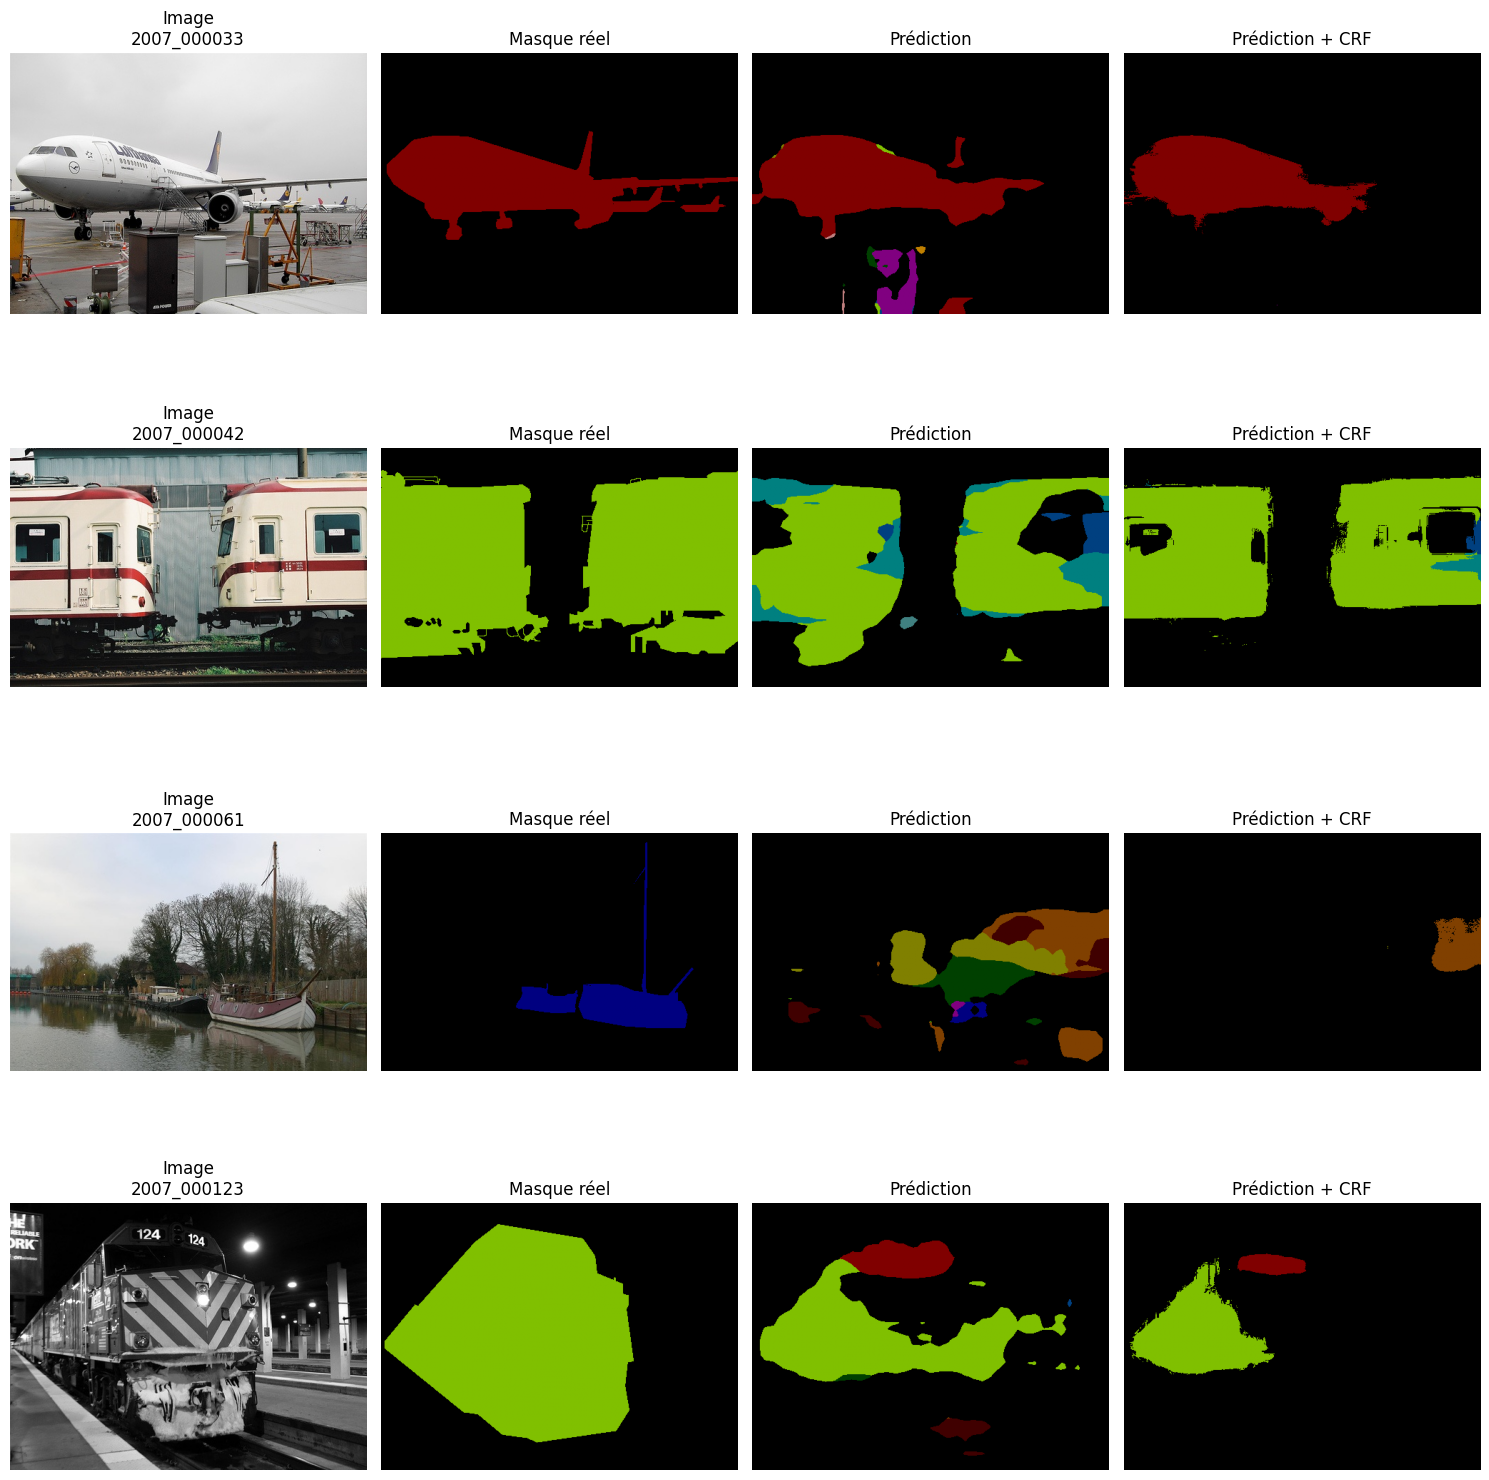

In [ ]:
show_crf_comparison(model, DATA_DIR,
                    split="val",num_images=4,
                    image_size=(IMAGE_SIZE,IMAGE_SIZE),
                    crf_params = crf_params,
                    voc_cmap=VOC_CMAP,
                    ignore_label=255)

